# Commercial Property Leasing Performance & Tenant Analytics
**Client:** commercial real-estate owner / property manager, Bulgaria (office, retail and mixed-use portfolio in Sofia, Plovdiv, Varna and Burgas)
**Engagement:** freelance BI analyst, Q1 2026, covering Jan-2021 to Dec-2025
**Stack:** PostgreSQL (pipeline + analysis SQL) · Python (pandas, matplotlib) · Tableau (dashboards)

> Tenant and building identities are replaced by codes under the client NDA. The published data is an anonymised rebuild with the same structure, volumes and data-quality issues as the original extracts.

### The brief
Leadership asked a simple question: **"Our portfolio looks ~94% let, so why is income growth lagging the market?"**
The asset team had dashboards for occupancy; nobody had connected occupancy to *re-letting time, renewal behaviour, service quality and cash collection*. This notebook walks through how each number was traced back to its cause.

### Questions
1. Where is occupancy (and income) being lost, building by building?
2. Why do some units stay vacant much longer than others?
3. Why do tenants leave at lease expiry?
4. Where is cash stuck in receivables?
5. What does all of this cost, and what should the team do first in 2026?

In [1]:
import sys, os
sys.path.append(os.path.abspath('../src'))
import pandas as pd
import matplotlib.pyplot as plt
from db import query, run_file

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

# chart style: one accent hue + neutral context, recessive grid
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#c9c8c3', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#ebeae6',
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'text.color': INK,
})
FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

## 1. Data overview
Seven extracts from the client's ERP (billing & receipts) and CAFM (maintenance) systems, plus a broker market-rent benchmark. Raw files are loaded as text into the `raw` schema, typed and cleaned into `clean`, and modelled as a star schema in `mart` (see `sql/01`–`04`).

In [2]:
counts = query('''
    SELECT 'raw.invoice_lines' AS table_name, COUNT(*) AS rows FROM raw.invoice_lines UNION ALL
    SELECT 'raw.payments', COUNT(*) FROM raw.payments UNION ALL
    SELECT 'raw.maintenance_tickets', COUNT(*) FROM raw.maintenance_tickets UNION ALL
    SELECT 'raw.leases', COUNT(*) FROM raw.leases UNION ALL
    SELECT 'raw.tenants', COUNT(*) FROM raw.tenants UNION ALL
    SELECT 'raw.units', COUNT(*) FROM raw.units UNION ALL
    SELECT 'raw.buildings', COUNT(*) FROM raw.buildings
''')
print(f"Total raw rows: {counts['rows'].sum():,}")
counts

Total raw rows: 819,587


,table_name,rows
0,raw.buildings,26
1,raw.units,3113
2,raw.tenants,4472
3,raw.leases,7111
4,raw.maintenance_tickets,32736
5,raw.payments,184013
6,raw.invoice_lines,588116


### Data quality
Every cleaning rule is logged in `clean.dq_log`. The most consequential fixes: **699 lease rents recorded in BGN** (converted at the fixed 1.95583 peg; left as-is they would have overstated rent by ~96%), **3,593 leases with non-ISO dates**, duplicate invoice lines and receipts that would double-count income and cash, and HVAC tickets logged under three different category names.

In [3]:
query('SELECT table_name, rule, rows_affected FROM clean.dq_log ORDER BY table_name, rows_affected DESC')

,table_name,rule,rows_affected
0,buildings,city spelling / whitespace / casing standardised,11
1,invoice_lines,charge_code casing / whitespace,29265
2,invoice_lines,comma decimal separator in amount,11713
3,invoice_lines,exact duplicate lines removed,1759
4,leases,"non-ISO date formats parsed (DD.MM.YYYY, DD/MM...",3593
5,leases,"currency label variants (eur, €) standardised",868
6,leases,rent recorded in BGN converted to EUR,699
7,leases,status casing standardised,436
8,maintenance_tickets,category synonyms / casing (e.g. Air condition...,2010
9,maintenance_tickets,priority casing,1332


## 2. Portfolio at 31-Dec-2025

In [4]:
kpi = run_file('a01_portfolio_kpis')
kpi.iloc[0].apply(lambda v: f'{v:,.0f}' if abs(v) >= 1000 else f'{v:,.2f}').to_frame('value')

,value
buildings,26.00
units,"3,113"
gla_sqm,"615,212"
occupancy_pct_dec25,94.00
net_rent_2025_eur,"104,964,196"
rent_free_leakage_pct,2.40
collection_rate_2025_pct,99.40
wault_years,1.87
gross_yield_pct,7.74


On the surface the portfolio is healthy: 94% occupied, 99% of 2025 billing collected, a 7.7% gross yield. The averages hide the problem, so the rest of the analysis goes building by building.

## 3. Where is occupancy being lost?

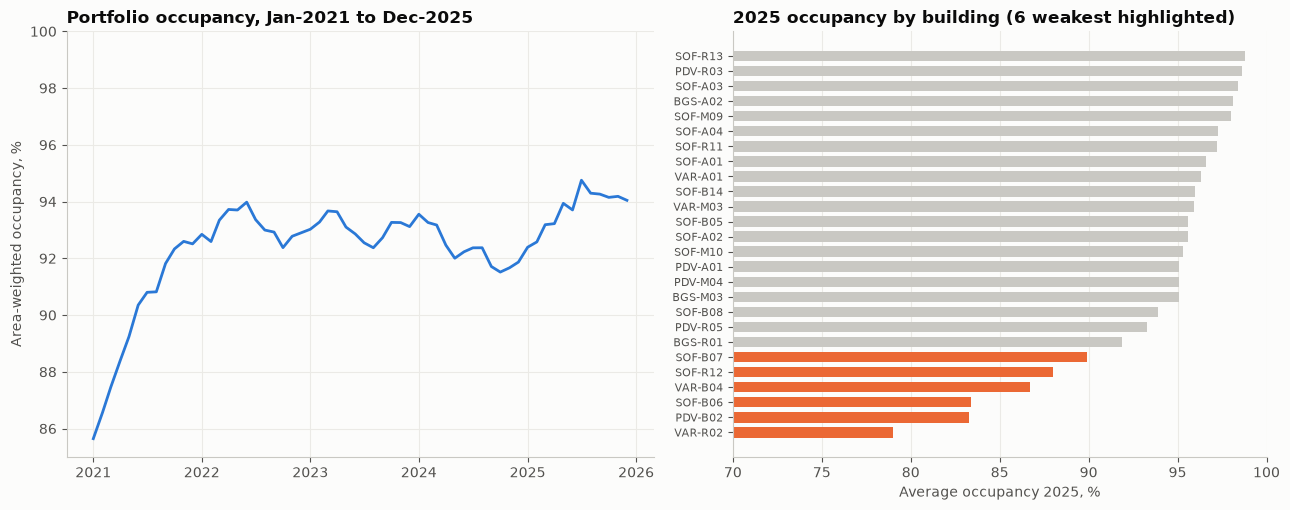

,building_code,city,asset_type,grade,occ_2021,occ_2023,occ_2025,avg_vacant_sqm_2025
0,VAR-R02,Varna,Retail,B,76.4,81.4,79.0,2770.0
1,PDV-B02,Plovdiv,Office,B,83.2,78.7,83.3,4293.0
2,SOF-B06,Sofia,Office,B,88.1,89.1,83.4,4703.0
3,VAR-B04,Varna,Office,B,82.4,83.0,86.7,3839.0
4,SOF-R12,Sofia,Retail,B,81.8,83.5,88.0,1841.0
5,SOF-B07,Sofia,Office,B,89.9,87.1,89.9,2786.0
6,BGS-R01,Burgas,Retail,B,84.8,92.0,91.9,1544.0
7,PDV-R05,Plovdiv,Retail,B,87.8,96.3,93.3,1118.0


In [5]:
trend = query('''
    SELECT month_start, SUM(area_sqm) FILTER (WHERE is_occupied) / SUM(area_sqm) AS occupancy
    FROM mart.fact_unit_month GROUP BY 1 ORDER BY 1
''')
occ = run_file('a02_occupancy_trend')

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
ax.plot(pd.to_datetime(trend['month_start']), trend['occupancy'] * 100, color=BLUE, lw=2)
ax.set_ylim(85, 100); ax.set_ylabel('Area-weighted occupancy, %')
ax.set_title('Portfolio occupancy, Jan-2021 to Dec-2025')

ax = axes[1]
o = occ.sort_values('occ_2025')
bottom = set(o['building_code'].head(6))
colors = [ORANGE if b in bottom else GREY for b in o['building_code']]
ax.barh(o['building_code'], o['occ_2025'], color=colors, height=0.7)
ax.set_xlim(70, 100); ax.set_xlabel('Average occupancy 2025, %'); ax.tick_params(axis='y', labelsize=8)
ax.set_title('2025 occupancy by building (6 weakest highlighted)')
ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, '01_occupancy'); plt.show()

occ.head(8)

In [6]:
v = occ.assign(bottom=occ['building_code'].isin(bottom))
gla = query('SELECT building_code, gla_sqm FROM mart.dim_building')
v = v.merge(gla, on='building_code')
print(f"Bottom-6 share of 2025 vacant sqm: {v.loc[v.bottom,'avg_vacant_sqm_2025'].sum()/v['avg_vacant_sqm_2025'].sum():.1%}")
print(f"Bottom-6 share of GLA:            {v.loc[v.bottom,'gla_sqm'].sum()/v['gla_sqm'].sum():.1%}")

Bottom-6 share of 2025 vacant sqm: 52.4%
Bottom-6 share of GLA:            22.6%


**Finding.** Six buildings, all grade B, hold **52%** of the portfolio's vacant space in 2025 while making up only 23% of GLA. The A-grade stock is effectively full. Two different stories sit inside these six buildings, and the next two sections separate them: **pricing** (SOF-B06, PDV-B02, VAR-B04, SOF-R12) and **service quality** (SOF-B07, VAR-R02).

## 4. Why do some units stay empty so long?
Vacancy spells were rebuilt from the unit × month grain with a gaps-and-islands query (`a03_vacancy_pricing.sql`), then compared with how far each unit's **asking rent** sits above the **broker market benchmark** for the same city, use and grade.

In [7]:
bands = run_file('a03_vacancy_pricing')
bands

,asking_vs_market_band,vacancy_spells,avg_months_to_relet,median_months_to_relet,pct_vacant_12m_plus
0,1. at market (<= +5%),701,5.2,3.0,9.3
1,2. +5% to +15%,317,6.6,4.0,17.0
2,3. +15% to +25%,215,7.2,5.0,19.1
3,4. above +25%,161,7.7,5.0,21.7


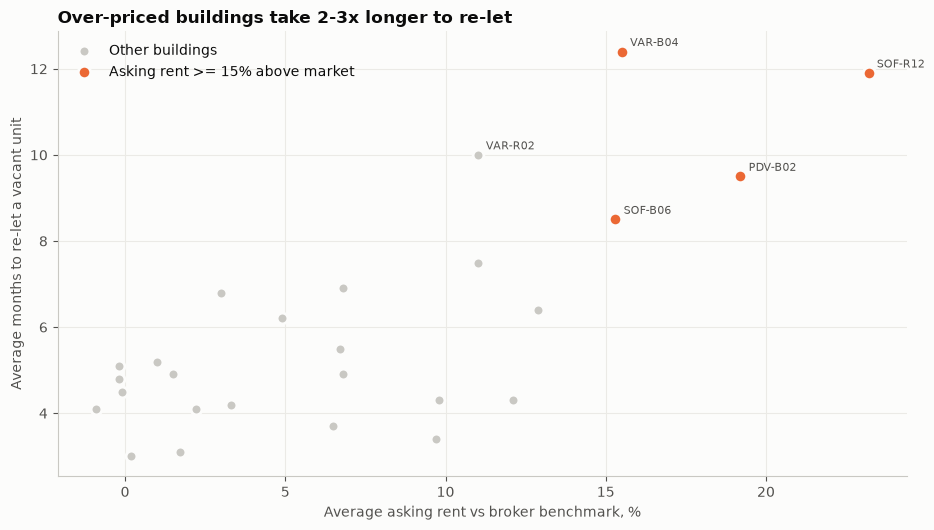

In [8]:
pb = run_file('a03b_pricing_by_building')
over = pb['avg_asking_vs_market_pct'] >= 15

fig, ax = plt.subplots(figsize=(9.5, 5.4))
ax.scatter(pb.loc[~over, 'avg_asking_vs_market_pct'], pb.loc[~over, 'avg_months_to_relet'], s=60, color=GREY,
           edgecolor='#fcfcfb', linewidth=2, label='Other buildings')
ax.scatter(pb.loc[over, 'avg_asking_vs_market_pct'], pb.loc[over, 'avg_months_to_relet'], s=80, color=ORANGE,
           edgecolor='#fcfcfb', linewidth=2, label='Asking rent >= 15% above market')
for _, r in pb[over | (pb['avg_months_to_relet'] >= 9)].iterrows():
    ax.annotate(r['building_code'], (r['avg_asking_vs_market_pct'], r['avg_months_to_relet']),
                xytext=(6, 4), textcoords='offset points', fontsize=8, color=MUTED)
ax.set_xlabel('Average asking rent vs broker benchmark, %')
ax.set_ylabel('Average months to re-let a vacant unit')
ax.set_title('Over-priced buildings take 2-3x longer to re-let')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout(); save(fig, '02_pricing_vs_reletting'); plt.show()

In [9]:
fair = pb.loc[pb['avg_asking_vs_market_pct'] < 10, 'avg_months_to_relet'].mean()
print(f"Avg months to re-let, buildings priced <10% above market: {fair:.1f}")
print(pb.loc[over, ['building_code', 'avg_asking_vs_market_pct', 'avg_months_to_relet']].to_string(index=False))

Avg months to re-let, buildings priced <10% above market: 4.7
building_code  avg_asking_vs_market_pct  avg_months_to_relet
      SOF-R12                      23.2                 11.9
      PDV-B02                      19.2                  9.5
      VAR-B04                      15.5                 12.4
      SOF-B06                      15.3                  8.5


**Finding.** Units asking more than 25% above the benchmark are **2.3x as likely** to sit empty for 12+ months as units priced at market. At building level the pattern is a *policy*, not noise: four grade-B buildings ask 15–23% above market and need 8.5–12.4 months to re-let, against ~4–5 months elsewhere. Their leasing team also concedes more rent-free months to defend the headline rent (see `a04_income_yield.sql`: VAR-B04 gives away 7.7% of gross rent), so the "protected" headline rent is not even being collected.

*Not the cause:* VAR-R02 and SOF-B07 are priced at market yet still have weak occupancy, so something else is going on there.

## 5. Why do tenants leave?
For every lease that expired inside the window (3,960), the analysis counts maintenance tickets that **breached their SLA in the 12 months before expiry**.

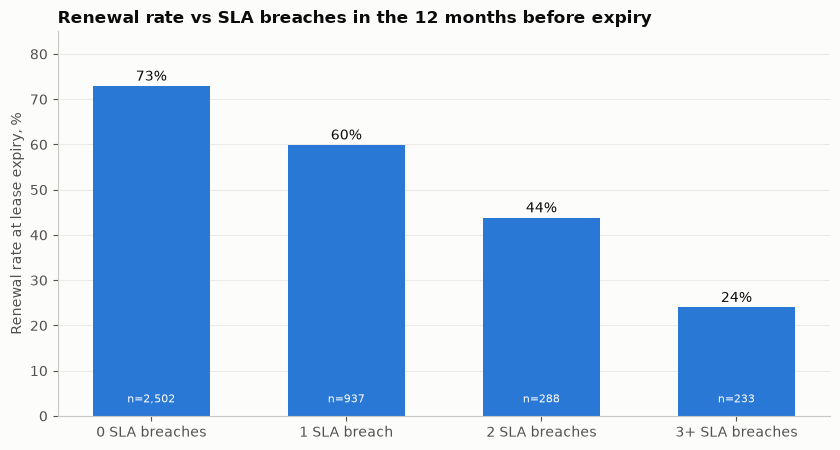

,complaint_band,expiries,renewed,renewal_rate_pct,avg_tickets_12m,avg_satisfaction
0,0 SLA breaches,2502,1825,72.9,1.3,4.27
1,1 SLA breach,937,561,59.9,2.6,3.63
2,2 SLA breaches,288,126,43.8,3.9,3.39
3,3+ SLA breaches,233,56,24.0,6.6,3.28
4,All expiries,3960,2568,64.8,2.1,3.89


In [10]:
ren = run_file('a06_renewal_drivers')
plot = ren[ren['complaint_band'] != 'All expiries']
fig, ax = plt.subplots(figsize=(8.5, 4.6))
bars = ax.bar(plot['complaint_band'], plot['renewal_rate_pct'], color=BLUE, width=0.6)
for b, n in zip(bars, plot['expiries']):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f"{b.get_height():.0f}%", ha='center', fontsize=10, color=INK)
    ax.text(b.get_x() + b.get_width()/2, 3, f"n={n:,}", ha='center', fontsize=8, color='white')
ax.set_ylim(0, 85); ax.set_ylabel('Renewal rate at lease expiry, %')
ax.set_title('Renewal rate vs SLA breaches in the 12 months before expiry')
ax.grid(axis='x', visible=False)
fig.tight_layout(); save(fig, '03_renewal_vs_sla'); plt.show()
ren

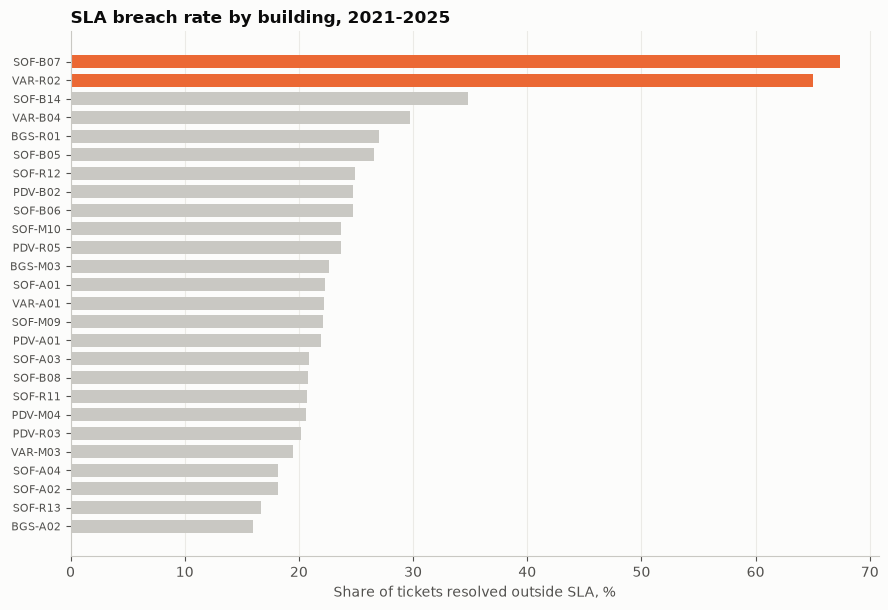

,building_code,year_built,tickets,tickets_per_1000_sqm,sla_breach_pct,hvac_breach_pct,hvac_share_pct,median_resolution_h,avg_satisfaction
0,SOF-B07,1998,3327,121.1,67.4,74.2,42.2,101.05,3.30
1,VAR-R02,2006,2037,154.2,65.0,73.1,42.7,92.55,3.31
2,SOF-B14,2003,1787,69.0,34.8,39.0,19.4,52.05,3.78
3,VAR-B04,2002,1491,51.7,29.7,28.2,18.3,45.25,3.83
4,BGS-R01,2009,1086,56.7,27.0,30.5,19.3,43.65,3.91


In [11]:
sla = run_file('a07_maintenance_sla')
s = sla.sort_values('sla_breach_pct')
fig, ax = plt.subplots(figsize=(9, 6.2))
colors = [ORANGE if x > 50 else GREY for x in s['sla_breach_pct']]
ax.barh(s['building_code'], s['sla_breach_pct'], color=colors, height=0.7)
ax.set_xlabel('Share of tickets resolved outside SLA, %'); ax.tick_params(axis='y', labelsize=8)
ax.set_title('SLA breach rate by building, 2021-2025')
ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, '04_sla_by_building'); plt.show()
sla.head(5)

**Finding.** Renewal falls from **73%** for tenants with no SLA breaches to **24%** for tenants with three or more. The breaches are not spread across the portfolio: **SOF-B07 (built 1998) and VAR-R02** breach SLA on two thirds of their tickets, roughly 3x the rest, and HVAC is ~42% of their workload with a 73–74% breach rate. These are the two lowest-renewal buildings in the portfolio (35% and 37%).

The question the asset team originally asked was "how do we fill the vacant units?". The data says the more urgent question is "**why are we creating vacancies in buildings tenants would otherwise stay in?**"

## 6. Where is cash stuck?

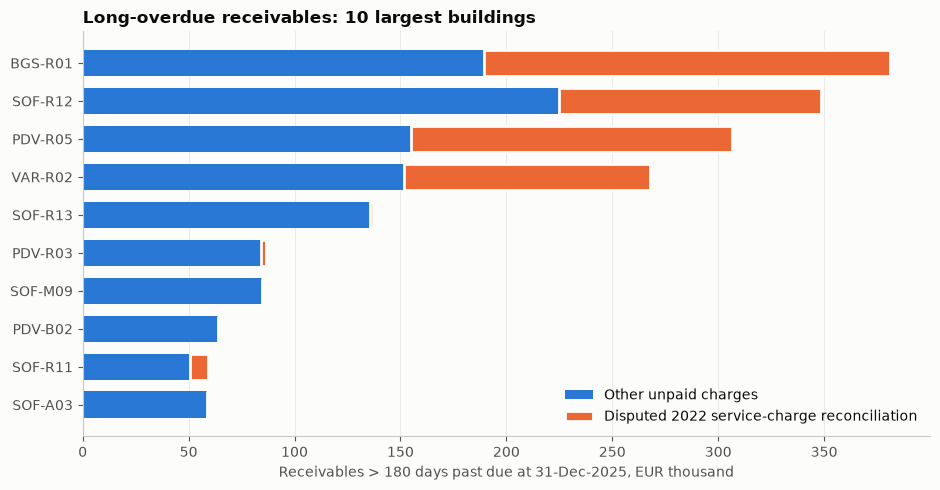

180+ day receivables: EUR 2,437,036; 4 retail buildings: EUR 1,303,607 (53%)


In [12]:
ar = run_file('a05_receivables_aging').fillna(0)
top = ar.sort_values('d180_plus', ascending=False).head(10).iloc[::-1]
other = top['d180_plus'] - top['d180_from_sc_recon']
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.barh(top['building_code'], other / 1e3, color=BLUE, height=0.7, label='Other unpaid charges')
ax.barh(top['building_code'], top['d180_from_sc_recon'] / 1e3, left=other / 1e3, color=ORANGE, height=0.7,
        edgecolor='#fcfcfb', linewidth=2, label='Disputed 2022 service-charge reconciliation')
ax.set_xlabel('Receivables > 180 days past due at 31-Dec-2025, EUR thousand')
ax.set_title('Long-overdue receivables: 10 largest buildings')
ax.legend(frameon=False, loc='lower right'); ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, '05_receivables_180'); plt.show()

dispute = ['BGS-R01', 'SOF-R12', 'PDV-R05', 'VAR-R02']
tot = ar['d180_plus'].sum(); d = ar.loc[ar['building_code'].isin(dispute), 'd180_plus'].sum()
print(f"180+ day receivables: EUR {tot:,.0f}; 4 retail buildings: EUR {d:,.0f} ({d/tot:.0%})")

In [13]:
run_file('a09_sc_reconciliation')

,service_year,asset_type,reconciliation_billed_eur,still_open_eur,invoices_open
0,2021,Mixed,-84906.0,0.0,0
1,2021,Office,-252163.0,0.0,0
2,2021,Retail,-114801.0,0.0,0
3,2022,Mixed,1481279.0,4142.0,1
4,2022,Office,4410378.0,12124.0,5
5,2022,Retail,2212707.0,604856.0,235
6,2023,Mixed,-807751.0,0.0,0
7,2023,Office,-2268909.0,0.0,0
8,2023,Retail,-1155914.0,0.0,0
9,2024,Mixed,-518247.0,0.0,0


**Finding.** Collection looks excellent at portfolio level (99.4%), but **over half of the >180-day balance sits in four grade-B retail buildings**, and the single biggest component is the **2022 service-charge reconciliation** billed in March 2023, after the energy-price shock. Office tenants paid it; ~27% of the retail amount is still open almost three years later. This is a dispute, not a credit problem: the same tenants pay their monthly rent on time. It needs a commercial settlement (payment plans or a partial write-off against lease extensions), not more reminder letters.

## 7. What does it cost?

In [14]:
lost = run_file('a08_renewal_by_building')
lost.head(10)

,building_code,expiries,renewal_rate_pct,lost_rent_eur
0,SOF-B07,148,34.5,1740177.0
1,VAR-R02,129,37.2,1627561.0
2,SOF-B06,150,55.3,1920406.0
3,SOF-B05,147,57.1,909931.0
4,SOF-B14,128,58.6,801824.0
5,VAR-B04,143,60.1,1633437.0
6,PDV-B02,131,61.1,1530959.0
7,PDV-M04,138,61.6,692827.0
8,SOF-R12,140,62.9,1752686.0
9,BGS-M03,165,64.8,646410.0


In [15]:
svc = lost.loc[lost['building_code'].isin(['SOF-B07', 'VAR-R02']), 'lost_rent_eur'].sum()

# over-pricing: vacancy months beyond what fairly priced buildings need, valued at benchmark rent
price_b = ['SOF-B06', 'PDV-B02', 'VAR-B04', 'SOF-R12']
ps = query('''
    SELECT building_code, months_vacant, area_sqm, benchmark_rent_eur_sqm
    FROM tableau.vacancy_spells WHERE is_complete_spell = 1
''')
ps = ps[ps['building_code'].isin(price_b)]
price_cost = ((ps['months_vacant'] - fair).clip(lower=0) * ps['area_sqm'] * ps['benchmark_rent_eur_sqm']).sum()

recon_open = run_file('a09_sc_reconciliation')['still_open_eur'].sum()

impact = pd.DataFrame({
    'driver': ['Service failures (SOF-B07, VAR-R02): rent lost while units of departed tenants stood empty',
               'Over-pricing (4 buildings): vacancy beyond fairly priced buildings, at benchmark rent',
               'Disputed 2022 service-charge reconciliation still unpaid (cash, one-off)'],
    'eur_2021_2025': [svc, price_cost, recon_open],
})
impact['eur_per_year'] = [svc / 5, price_cost / 5, float('nan')]
impact.round(0)

,driver,eur_2021_2025,eur_per_year
0,"Service failures (SOF-B07, VAR-R02): rent lost...",3367738.0,673548.0
1,Over-pricing (4 buildings): vacancy beyond fai...,3497823.0,699565.0
2,Disputed 2022 service-charge reconciliation st...,621122.0,NaN


**Finding.** The two causes cost roughly the same: **~EUR 0.67M a year** from tenants lost to service failures in two buildings and **~EUR 0.70M a year** from over-priced space standing empty in four others, together about **1.3% of annual net rent**, plus **EUR 0.62M** of cash tied up in the reconciliation dispute. None of it shows up in the 94% headline occupancy.

*Method note:* lost rent counts only the months a unit stood empty after a non-renewal, valued at the departing tenant's contract rent. Fit-out contributions, agent fees and rent-free on the replacement lease are excluded, so the figures are conservative.

## 8. Proactive: who is at risk in 2026?
Using the same driver, every active lease expiring in 2026 is scored by its SLA breaches in 2025. The leasing team gets this list 6–12 months before expiry instead of discovering the non-renewal at notice date.

In [16]:
wl = run_file('a10_retention_watchlist')
summary = (wl.groupby('churn_risk')
             .agg(leases=('lease_id', 'count'), rent_pa_eur=('contract_rent_pa_eur', 'sum'))
             .reindex(['High', 'Medium', 'Low']))
summary['share_of_rent'] = (summary['rent_pa_eur'] / summary['rent_pa_eur'].sum()).round(3)
print(summary.to_string())
wl.head(10)

            leases  rent_pa_eur  share_of_rent
churn_risk                                    
High            51    1629519.0          0.059
Medium         268   10978787.0          0.397
Low            504   15057635.0          0.544


,lease_id,tenant_id,building_code,unit_code,area_sqm,segment,industry,end_date,contract_rent_pa_eur,tickets_12m,sla_breaches_12m,churn_risk
0,L001651,T01040,SOF-B07,SOF-B07-06059,442.5,Mid,IT & Software,2026-08-31,53206.0,18,13,High
1,L001729,T01102,SOF-B07,SOF-B07-09097,783.0,Large,Media & Marketing,2026-01-31,89920.0,16,9,High
2,L005600,T03474,VAR-R02,VAR-R02-01062,111.9,SME,Fashion & Apparel,2026-11-30,21391.0,12,9,High
3,L001573,T00972,SOF-B07,SOF-B07-05021,271.9,Mid,BPO / Shared Services,2026-03-31,46854.0,11,8,High
4,L001656,T01043,SOF-B07,SOF-B07-07061,298.1,Mid,BPO / Shared Services,2026-06-30,44143.0,8,8,High
5,L001773,T01135,SOF-B07,SOF-B07-04117,383.8,Mid,Engineering,2026-05-31,54991.0,8,7,High
6,L005703,T03556,VAR-R02,VAR-R02-00108,253.6,Mid,Food & Beverage,2026-01-31,44339.0,9,6,High
7,L005579,T03459,VAR-R02,VAR-R02-00054,313.3,Mid,Fashion & Apparel,2026-05-31,43348.0,11,6,High
8,L001576,T00975,SOF-B07,SOF-B07-05023,281.4,Mid,IT & Software,2026-04-30,32384.0,8,6,High
9,L005681,T03540,VAR-R02,VAR-R02-02098,131.8,SME,Services,2026-01-31,24799.0,8,6,High


## 9. Recommendations (as presented to leadership)

| # | Action | Owner | Why (evidence) |
|---|---|---|---|
| 0 | **Watch-list above to the leasing team now**: 51 high-risk leases (EUR 1.6M rent p.a.) expire in 2026 | Leasing | Lead time is the only lever once a tenant is unhappy |
| 1 | **HVAC remediation + SLA recovery plan for SOF-B07 and VAR-R02** before chasing new tenants there | Facility management | 2/3 of tickets breach SLA; renewal 35–37% vs 65% portfolio |
| 2 | **Retention calls for 2026 "High" risk leases** 9 months before expiry, starting with the largest rents | Leasing | Tenants with 3+ breaches renew at 24% |
| 3 | **Re-price vacant units in SOF-B06, PDV-B02, VAR-B04, SOF-R12** to within 5% of benchmark; trade headline rent for term, not rent-free | Asset management | 8.5–12.4 months to re-let vs ~4.6; higher rent-free leakage |
| 4 | **Settle the 2022 service-charge dispute** in the four retail centres (instalment plans tied to lease extensions) | Finance + leasing | > 50% of 180+ day arrears; tenants otherwise pay on time |
| 5 | Make **SLA breach rate a standing KPI** in the monthly asset review and the Tableau dashboard | BI / asset management | Leading indicator of non-renewal, 6–12 months ahead |

*One-line version for the board:* **we are not short of demand; we lose tenants we already have through slow repairs, and we keep space empty by asking above market.**